# Processing M+1 experimental data

This tutorial shows how to use Orbitrap M+1 measurements of a sample and standard to compute site-specific δ values. It uses the alanine dataset from Weiss et al., 2023, which is included with the isotomics package. The original publication used FTStatistic; I later went and processed these with isox, and the isox files are used in this tutorial. You can access the data files and explore them yourself via...

The code in this tutorial is identical to that in the `isotomics-quickstart`.

In [1]:
from importlib import resources
from pathlib import Path

import pandas as pd

from isotomics import dataAnalyzerMNIsoX as dA
from isotomics import dataScreenIsoX as dataScreen
from isotomics import organizeData
from isotomics import solveExperimentalData

DATA = resources.files("isotomics") / "input_data"
MOLECULE_INPUT_PATH = str(DATA / "Example_Molecule_Input.csv")
EXPERIMENTAL_DATA = DATA / "Experimental_Data"

## 1. How the data are organized

The experimental data are organized into one folder per experiment:

- 1: '44', for the 44 fragment. This was a M+1 experiment which selected the M+1 isotopologues, fragmented them, and observed the 44 fragment. 
- 2: 'full_molecular_average' for the molecular average data. This experiment observed the unsubstituted isotopologue as well as singly-substituted 13C, 15N, 2H, and 18O peaks in the intact molecule. 
- 3: 'full_relative_abundance' is the 'full' fragment (i.e., observations of the M+1 relative abundances within the intact molecule). A bit confusingly, we use the same dataset as that in full_molecular_average, **except** that only the data for 13C, 15N, and 2H were extracted. For our purposes, the M+1 relative abundances from that measurement were sufficiently precise to be useful, and so we could save measurement time by reusing the data in this way. In other work, it may be preferable to do two separate experiments; once, including unsub, to get the molecular average U values (13C/unsub, 15N/unsub; what we report in (2)); and a separate experiment with a narrow mass window, excluding unsub, in order to get the M+1 relative abundances (13C / (13C + 15N + 2H)). 

With each folder, we have subdirectories for 'Smp' and 'Std' measurements.

:::{important}
Each `.isox` file must contain a single fragment (one IsoX compound). isotomics identifies peaks by
their isotopolog name only, so several fragments in one file would be mixed together; it raises an
error if a file contains more than one compound. Export each compound to its own file, and keep each
fragment's files in its own folder.
:::

In [2]:
for folder in sorted(EXPERIMENTAL_DATA.iterdir()):
    if folder.is_dir():
        for kind in ("Smp", "Std"):
            n = len(list((folder / kind).glob("*.isox")))
            print(f"{folder.name}/{kind}/  {n} files")

44/Smp/  3 files
44/Std/  4 files
full_molecular_average/Smp/  3 files
full_molecular_average/Std/  6 files
full_relative_abundance/Smp/  3 files
full_relative_abundance/Std/  6 files


Note that the fragment names match the `Fragment` columns of the molecule CSV from
{doc}`simulation_workflow`.

:::{note}
isotomics labels deuterium `2H`, like the other isotopes. Older data, including these raw `.isox`
files, may label it `D`; it is renamed to `2H` when read, with a one-time warning. The same applies
to error files, already-processed tables, and substitution names passed to functions (for example
`omitMeasurements={'M1': {'44': ['D']}}` or `UValue='D/Unsub'`).
:::

## 2. Process the files

`processIndividualAndAverageIsotopeRatios` is a function which reads each file and computes many ratios of interest. It first selects only those scans within `time_bounds`, applied universally to each file. It additionally computes isotope ratios and M+1 relative abundances. There are a few peak screening tools which are active. Note that these were current in 2024 and developed prior to then, and that new innovations in Orbitrap-IRMS may offer better ways to accomplish the same tasks. 

The screens only print warnings, and it is up to you to decide what to do with these warnings. 

- `peakDriftScreen` (`peakDriftThreshold`, in ppm): for each file, compares the observed mass difference
  between each peak and the most abundant peak with the theoretical spacing between them. Flags differences larger than the threshold, which suggest the peak drifted (perhaps due to coalescence) or the wrong peak is being extracted. 
- `zeroCountsScreen` (`zeroCountsThreshold`, a fraction of scans): counts the scans in which each
  peak was not detected (zero counts), and warns if that fraction exceeds the threshold. At 0, any
  missing scan is reported. Frequent dropouts usually mean a peak is near the detection limit (often
  ²H or multiply substituted peaks), which biases its average.
- `RSESNScreen` (`RSESNThreshold`, default 2): compares each measurement's relative standard error
  with its shot-noise limit, computed from the ion counts of the peaks involved. In theory, a value near 1 means the measurement is as precise as it could be based on counting statistics. In practice, we find typical values around 1.4, which may be because we have a poor grasp of how many ions we are actually observing (calculated using the CN constant). Either way, values significantly above the norm, e.g., > 2, suggest something is harming precision. 
  
For the alanine data below, none of the screens report a problem.


In [3]:
fragmentFolderPaths = organizeData.get_subfolder_paths(str(EXPERIMENTAL_DATA))

rtnMeans, rtnMergedDict = dA.processIndividualAndAverageIsotopeRatios(
    fragmentFolderPaths,
    Path.cwd(),
    outputToCSV=True,
    csvOutputPath="all_data_output.csv",
    file_extension=".isox",
    processed_data_subfolder=".",
    time_bounds=(5, 15),
    peakDriftScreen=True,
    peakDriftThreshold=2,       # ppm
    zeroCountsScreen=True,
    zeroCountsThreshold=0,
    RSESNScreen=True,
)

Processing fragment folder: 44
  - <isotomics>\input_data\Experimental_Data\44\Smp\20211006_07_Alanine_C1-1_M1_rep1.isox
  - <isotomics>\input_data\Experimental_Data\44\Smp\20211006_09_Alanine_C1-1_M1_rep2.isox
  - <isotomics>\input_data\Experimental_Data\44\Smp\20211006_11_Alanine_C1-1_M1_rep3.isox
  - <isotomics>\input_data\Experimental_Data\44\Std\20211006_06_Alanine_Unlab_M1_rep1.isox
  - <isotomics>\input_data\Experimental_Data\44\Std\20211006_08_Alanine_Unlab_M1_rep2.isox
  - <isotomics>\input_data\Experimental_Data\44\Std\20211006_10_Alanine_Unlab_M1_rep3.isox
  - <isotomics>\input_data\Experimental_Data\44\Std\20211006_12_Alanine_Unlab_M1_rep4.isox


<isotomics>\dataAnalyzerMNIsoX.py:353: UserWarning: Renamed deuterium label 'D' to '2H' in .isox data; isotomics uses '2H'.
  thisIsoX = readIsoX(isoXFileName)


Processing fragment folder: full_molecular_average
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Smp\20221209_10_TTAS_C1-1_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Smp\20221209_11_TTAS_C1-1_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Smp\20221209_12_TTAS_C1-1_Rep_3.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_07_TTAS_Unlab_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_08_TTAS_Unlab_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_09_TTAS_Unlab_Rep_3.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_13_TTAS_Unlab_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_14_TTAS_Unlab_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_molecular_average\Std\20221209_15_TTAS_Unlab_Rep_3.iso

Processing fragment folder: full_relative_abundance
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Smp\20221209_10_TTAS_C1-1_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Smp\20221209_11_TTAS_C1-1_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Smp\20221209_12_TTAS_C1-1_Rep_3.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_07_TTAS_Unlab_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_08_TTAS_Unlab_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_09_TTAS_Unlab_Rep_3.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_13_TTAS_Unlab_Rep_1.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_14_TTAS_Unlab_Rep_2.isox
  - <isotomics>\input_data\Experimental_Data\full_relative_abundance\Std\20221209_15_TTAS_Unlab

`processIndividualAndAverageIsotopeRatios` returns both `rtnMeans` and `rtnMergedDict`. `rtnMeans` is a summary of the processed data, used by the solver, while `rtnMergedDict` contains scan by scan data and can be useful for further analysis. 

Within `rtnMeans`: 
- `Fragment`: gives the measurement folder the data originates from. 
- `MN Relative Abundance` or `IsotopeRatio`: states what was measured. Either specifies the peak (`13C`, `15N`, `2H`, `Unsub`) for M+N relative abundance or gives the ratio explicitly, such as `13C/Unsub`.
- `Average`, `StdDev`, `StdError`, `RelStdError`: The mean of the corresponding ratio and several statements about its uncertainty. 
- `ShotNoise` and `RSE over SN`: the relative standard error to shot-noise ratio.  Values near 1 mean the measurement is close to shot-noise
  limited.
- `Tic`, `TicVar`: total ion current and its variability.

The second object, `rtnMergedDict`, keeps the scan-level data for every file, with the file paths as keys. 
Each entry gives a list of peaks found (`subNameList`) as well as `mergedDf`, a table with one row per
scan:

In [4]:
rtnMeans

,MN Relative Abundance,IsotopeRatio,File Type,Average,StdDev,StdError,RelStdError,ShotNoise,Tic,TicVar,RSE over SN,Fragment
0,13C,NaN,Smp,0.674226,0.007777,0.000054,0.000080,0.000099,1.266048e+06,0.000000,1.398728,44
1,13C,NaN,Std,0.677952,0.007894,0.000047,0.000070,0.000101,1.276330e+06,0.000000,1.387752,44
2,15N,NaN,Smp,0.109943,0.005016,0.000035,0.000317,0.000406,1.266048e+06,0.000000,1.351475,44
3,15N,NaN,Std,0.110460,0.005125,0.000031,0.000279,0.000415,1.276330e+06,0.000000,1.342991,44
4,2H,NaN,Smp,0.025855,0.002637,0.000018,0.000709,0.000877,1.266048e+06,0.000000,1.400373,44
5,2H,NaN,Std,0.026000,0.002681,0.000016,0.000619,0.000895,1.276330e+06,0.000000,1.383660,44
6,Unsub,NaN,Smp,0.189975,0.006837,0.000048,0.000250,0.000295,1.266048e+06,0.000000,1.469179,44
7,Unsub,NaN,Std,0.185588,0.006882,0.000041,0.000223,0.000306,1.276330e+06,0.000000,1.453885,44
8,NaN,13C/Unsub,Smp,0.036229,0.001306,0.000017,0.000469,0.000658,1.035942e+08,0.073282,1.235063,full_molecular_average
9,NaN,13C/Unsub,Std,0.035811,0.001301,0.000012,0.000334,0.000661,1.026639e+08,0.079299,1.239504,full_molecular_average


In [5]:
oneFile = next(iter(rtnMergedDict))
print(Path(oneFile).name, rtnMergedDict[oneFile]["subNameList"])
rtnMergedDict[oneFile]["mergedDf"][["scanNumber", "retTime", "tic", "counts13C", "counts15N", "counts2H", "countsUnsub"]].head()

20211006_07_Alanine_C1-1_M1_rep1.isox ['13C', '15N', '2H', 'Unsub']


,scanNumber,retTime,tic,counts13C,counts15N,counts2H,countsUnsub
3048,3049,5.001,1157972.1,4257.701455,791.598640,181.425943,1204.036483
3049,3050,5.002,1248563.5,4964.387552,797.947497,160.428252,1369.925752
3050,3051,5.004,1241255.5,5376.881117,863.316363,215.807341,1470.183127
3051,3052,5.005,1344940.2,5563.364686,811.149345,209.434704,1566.638312
3052,3053,5.007,1267379.2,5422.913387,869.096278,200.048210,1561.154122


This is the data the screening step below plots.

## 3. Check signal stability

Before trusting the averages, look at how each acquisition behaves over time.
`visualizeTICVersusTime` plots a ratio or relative abundance for every scan of one file, with a
moving average, and a histogram on the right. If the signal is unstable early or late in the
acquisition, change `time_bounds` above and reprocess.

<isotomics>\dataScreenIsoX.py:221: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  cAx.legend()


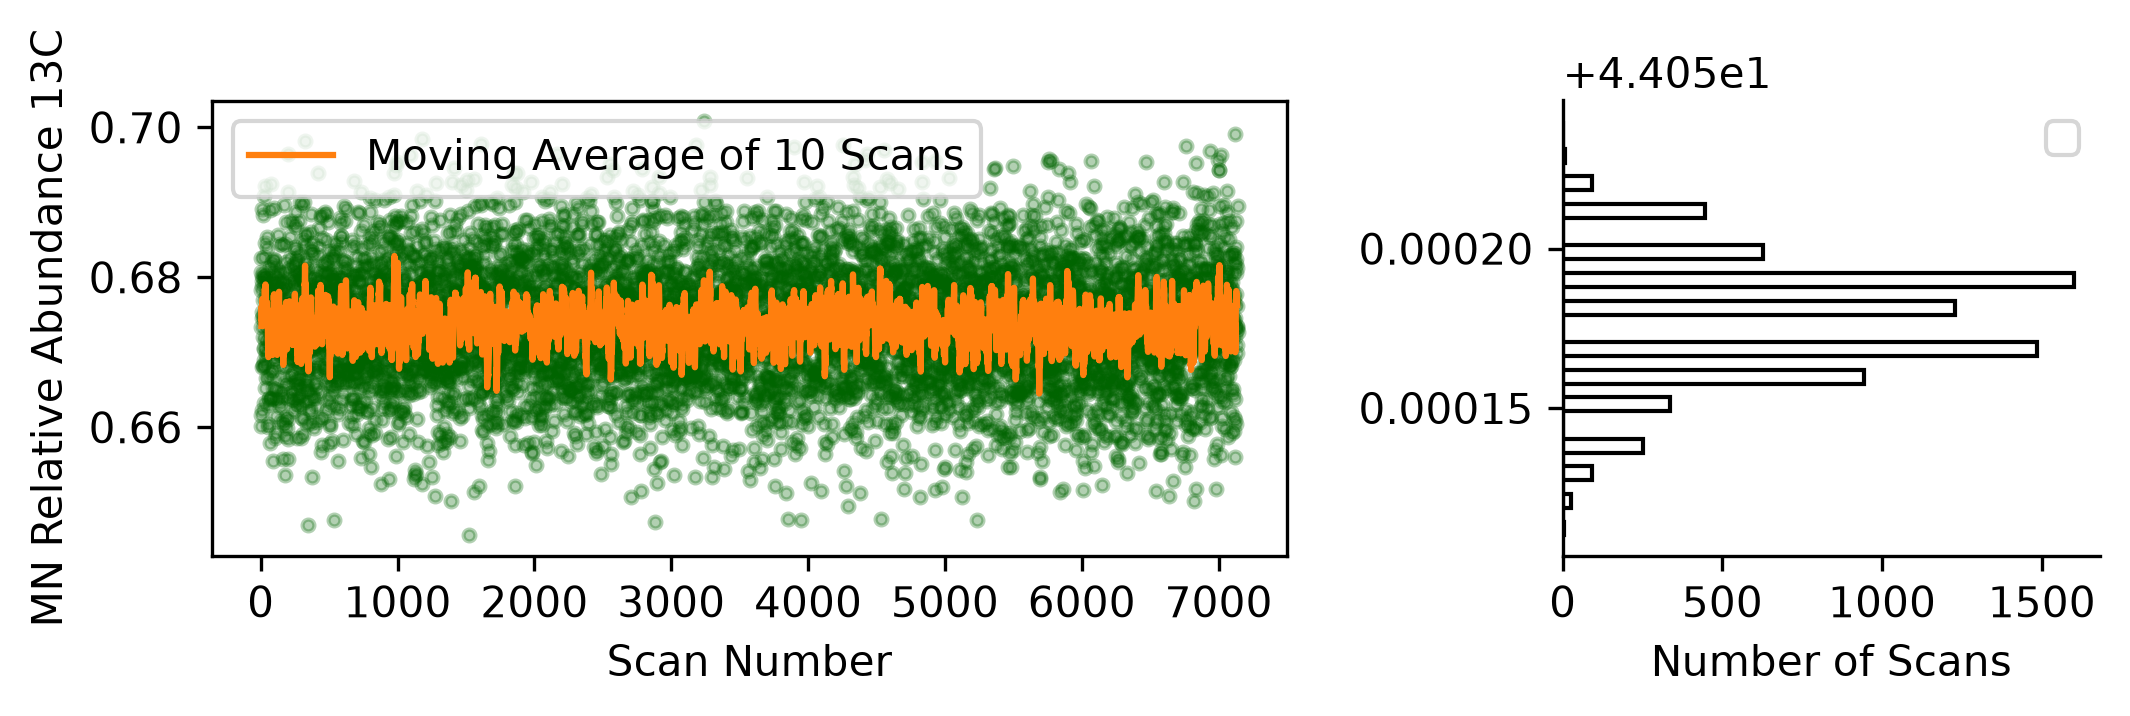

In [6]:
fileToScreen = next(f for f in rtnMergedDict if f.endswith("20211006_07_Alanine_C1-1_M1_rep1.isox"))

dataScreen.visualizeTICVersusTime(
    fileName=fileToScreen,
    mergedDict=rtnMergedDict,
    targetRatio="13C",           # M+1 relative abundance of 13C; use e.g. "13C/Unsub" for ratios
    scan_averaging_number=10,
)

## 4. Solve for site-specific values

`experimentalDataM1` combines the processed measurements with:

- the molecule CSV,
- `STANDARD_DELTA_APPROX`, your best knowledge of the standard's site-specific composition
  (carbon sites known, the rest set to 0),
- the sample's molecular-average composition, used to convert M+1 relative abundances into
  site-specific values. Here it is δ¹³C = −0.8 ± 0.1 ‰ from an external (EA) measurement, so `mAObs=-0.8` and
  `mARelErr=0.0001` (errors are relative and given as fractions: 0.0001 = 0.1 ‰). To use
  the Orbitrap `full_molecular_average` data instead, set `mAObs` and `mARelErr` to `None`.

`perturbTheoryOAmt` controls a correction for low-abundance peaks. See the supplement to
Csernica and Eiler (2023) before changing it.

Writing experimental results to CSV: M1Output.csv
CSV write complete.


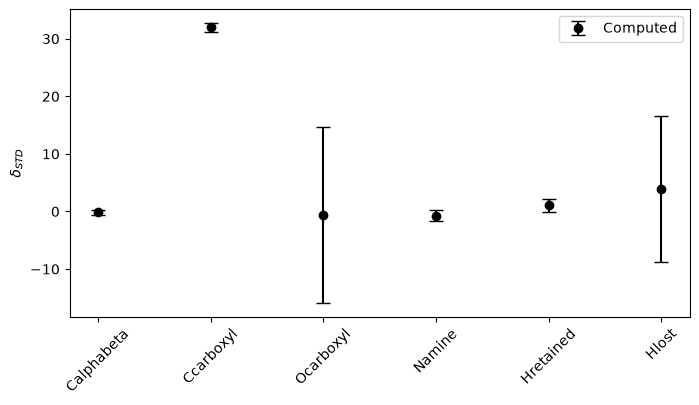

In [7]:
STANDARD_DELTA_APPROX = [-11.9, -9.95, 0, 0, 0, 0]  # Calphabeta, Ccarboxyl, Ocarboxyl, Namine, Hretained, Hlost

results = solveExperimentalData.experimentalDataM1(
    rtnMeans,
    Path.cwd(),
    MOLECULE_INPUT_PATH,
    STANDARD_DELTA_APPROX,
    UValue="13C/Unsub",
    mAObs=-0.8,
    mARelErr=0.0001,
    perturbTheoryOAmt=0.0003,
)

In [8]:
results[["IDS", "Number", "CRF Deltas", "CRF Deltas Error", "Relative Deltas", "Relative Deltas Error"]]

,IDS,Number,CRF Deltas,CRF Deltas Error,Relative Deltas,Relative Deltas Error
Calphabeta,C,2,-12.049,0.378,-0.151,0.382
Ccarboxyl,C,1,21.692,0.740,31.960,0.748
Ocarboxyl,O,2,-0.634,15.298,-0.634,15.298
Namine,N,1,-0.720,0.919,-0.720,0.919
Hretained,H,6,1.055,1.168,1.055,1.168
Hlost,H,2,3.891,12.755,3.891,12.755


`results` is a table with one row per site (also written to `M1Output.csv`):

- `IDS`, `Number`, `Fragment …`: the molecule definition from the CSV.
- `Relative Deltas` and `Relative Deltas Error`: the sample relative to the standard, from the
  Monte Carlo.
- `CRF Deltas` and `CRF Deltas Error`: the same results in the reference frame of
  `STANDARD_DELTA_APPROX`, which is repeated in `Standard Delta Values in CRF`.

The sample is enriched by about 32 ‰ in the carboxyl carbon relative to the standard, while the
α and β carbons are unchanged within error. The oxygen and lost-hydrogen sites are poorly
constrained because only the intact molecule sees them.

## Starting from already-processed data

If you process your raw data elsewhere, you can skip steps 1–3 and pass a table in the format
of `rtnMeans` directly. An example is bundled:

In [9]:
experimental_data = pd.read_csv(DATA / "Experimental_Data_Input.csv")
experimental_data.head()

,MN Relative Abundance,File Type,Average,StdError,RelStdError,Fragment,IsotopeRatio
0,13C,Smp,0.674226,0.000054,0.000080,44,NaN
1,13C,Std,0.677952,0.000055,0.000081,44,NaN
2,15N,Smp,0.109943,0.000035,0.000317,44,NaN
3,15N,Std,0.110460,0.000036,0.000322,44,NaN
4,2H,Smp,0.025855,0.000018,0.000709,44,NaN


In [10]:
results = solveExperimentalData.experimentalDataM1(
    experimental_data,
    Path.cwd(),
    MOLECULE_INPUT_PATH,
    STANDARD_DELTA_APPROX,
    UValue="13C/Unsub",
    mAObs=-0.8,
    mARelErr=0.0001,
    perturbTheoryOAmt=0.0003,
    plot=False,
)
results[["CRF Deltas", "CRF Deltas Error", "Relative Deltas", "Relative Deltas Error"]]

Writing experimental results to CSV: M1Output.csv
CSV write complete.


,CRF Deltas,CRF Deltas Error,Relative Deltas,Relative Deltas Error
Calphabeta,-12.050,0.394,-0.151,0.399
Ccarboxyl,21.693,0.774,31.961,0.782
Ocarboxyl,-0.591,15.617,-0.591,15.617
Namine,-0.711,1.054,-0.711,1.054
Hretained,1.046,1.256,1.046,1.256
Hlost,3.724,14.567,3.724,14.567


## Setting up your own data

`create_nested_folders` builds the folder layout from your molecule CSV. Copy your `.isox`
files into the `Smp` and `Std` folders it creates, then point this notebook at that folder:

```python
from isotomics import readCSVAndSimulate as sim

molecule = sim.moleculeFromCsv("My_Molecule.csv")
organizeData.create_nested_folders(
    fragment_dict=molecule["fragmentationDictionary"],
    parent_folder="My_Experiment",
)
```